In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix,
)
import joblib

FEATURES = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age",
]
TARGET = "Outcome"


In [ ]:
DATA_PATH = r"D:\kuliah\semester5\machinelearning\Healthcare-Diabetes.csv"

raw = pd.read_csv(DATA_PATH, sep=";")
raw.columns = raw.columns.str.strip()

print("Ukuran dataset:", raw.shape)
display(raw.head())


Ukuran dataset: (2768, 10)


,Id,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,1,6,148,72,35,0,33.6,0.627,50,1
1,2,1,85,66,29,0,26.6,0.351,31,0
2,3,8,183,64,0,0,23.3,0.672,32,1
3,4,1,89,66,23,94,28.1,0.167,21,0
4,5,0,137,40,35,168,43.1,2.288,33,1


In [5]:
required_columns = ["Id"] + FEATURES + [TARGET]
missing_columns = set(required_columns) - set(raw.columns)
if missing_columns:
    raise ValueError(f"Kolom tidak ditemukan: {missing_columns}")

print("Informasi tipe data dan nilai kosong:")
raw.info()

print("\nRingkasan statistik fitur:")
display(raw[FEATURES].describe().T)

print("\nJumlah label Outcome:")
print(raw[TARGET].value_counts(dropna=False).sort_index())


Informasi tipe data dan nilai kosong:
<class 'pandas.DataFrame'>
RangeIndex: 2768 entries, 0 to 2767
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        2768 non-null   int64  
 1   Pregnancies               2768 non-null   int64  
 2   Glucose                   2768 non-null   int64  
 3   BloodPressure             2768 non-null   int64  
 4   SkinThickness             2768 non-null   int64  
 5   Insulin                   2768 non-null   int64  
 6   BMI                       2768 non-null   float64
 7   DiabetesPedigreeFunction  2768 non-null   float64
 8   Age                       2768 non-null   int64  
 9   Outcome                   2768 non-null   int64  
dtypes: float64(2), int64(8)
memory usage: 216.4 KB

Ringkasan statistik fitur:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,2768.0,3.742775,3.323801,0.000,1.000,3.000,6.000,17.00
Glucose,2768.0,121.102601,32.036508,0.000,99.000,117.000,141.000,199.00
BloodPressure,2768.0,69.134393,19.231438,0.000,62.000,72.000,80.000,122.00
SkinThickness,2768.0,20.824422,16.059596,0.000,0.000,23.000,32.000,110.00
Insulin,2768.0,80.127890,112.301933,0.000,0.000,37.000,130.000,846.00
BMI,2768.0,32.137392,8.076127,0.000,27.300,32.200,36.625,80.60
DiabetesPedigreeFunction,2768.0,0.471193,0.325669,0.078,0.244,0.375,0.624,2.42
Age,2768.0,33.132225,11.777230,21.000,24.000,29.000,40.000,81.00



Jumlah label Outcome:
Outcome
0    1816
1     952
Name: count, dtype: int64


In [6]:
print("Missing value awal per kolom:")
print(raw.isna().sum())

print("\nJumlah nilai nol pada kolom pemeriksaan:")
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print((raw[zero_columns] == 0).sum())

n_duplicates = raw.duplicated(subset=FEATURES + [TARGET]).sum()
print("\nDuplikat pengukuran + Outcome (Id diabaikan):", n_duplicates)

# Periksa apakah pengukuran identik pernah diberi label berbeda
n_conflicts = (
    raw.groupby(FEATURES, dropna=False)[TARGET]
       .nunique()
       .gt(1)
       .sum()
)
print("Profil dengan Outcome yang bertentangan:", n_conflicts)


Missing value awal per kolom:
Id                          0
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Jumlah nilai nol pada kolom pemeriksaan:
Glucose            18
BloodPressure     125
SkinThickness     800
Insulin          1330
BMI                39
dtype: int64

Duplikat pengukuran + Outcome (Id diabaikan): 1990
Profil dengan Outcome yang bertentangan: 0


In [7]:
data = raw.drop_duplicates(subset=FEATURES + [TARGET]).copy()
data = data.drop(columns=["Id"])

ZERO_MEANS_MISSING = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]
for column in ZERO_MEANS_MISSING:
    data[column] = data[column].replace(0, np.nan)

if not set(data[TARGET].dropna().unique()).issubset({0, 1}):
    raise ValueError("Outcome harus berisi label 0 dan/atau 1 saja.")
data[TARGET] = data[TARGET].astype(int)

print("Ukuran setelah cleaning:", data.shape)
print("Missing value setelah nol diproses:")
print(data.isna().sum())
print("\nDistribusi Outcome setelah duplikat dihapus:")
print(data[TARGET].value_counts().sort_index())


Ukuran setelah cleaning: (778, 9)
Missing value setelah nol diproses:
Pregnancies                   0
Glucose                       5
BloodPressure                36
SkinThickness               229
Insulin                     377
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Distribusi Outcome setelah duplikat dihapus:
Outcome
0    506
1    272
Name: count, dtype: int64


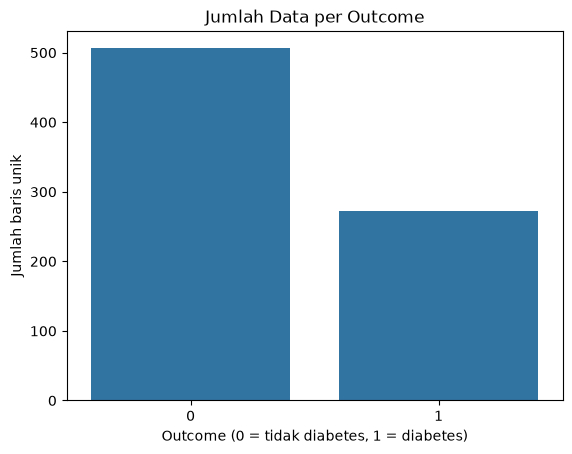

In [8]:
sns.countplot(data=data, x=TARGET)
plt.title("Jumlah Data per Outcome")
plt.xlabel("Outcome (0 = tidak diabetes, 1 = diabetes)")
plt.ylabel("Jumlah baris unik")
plt.show()


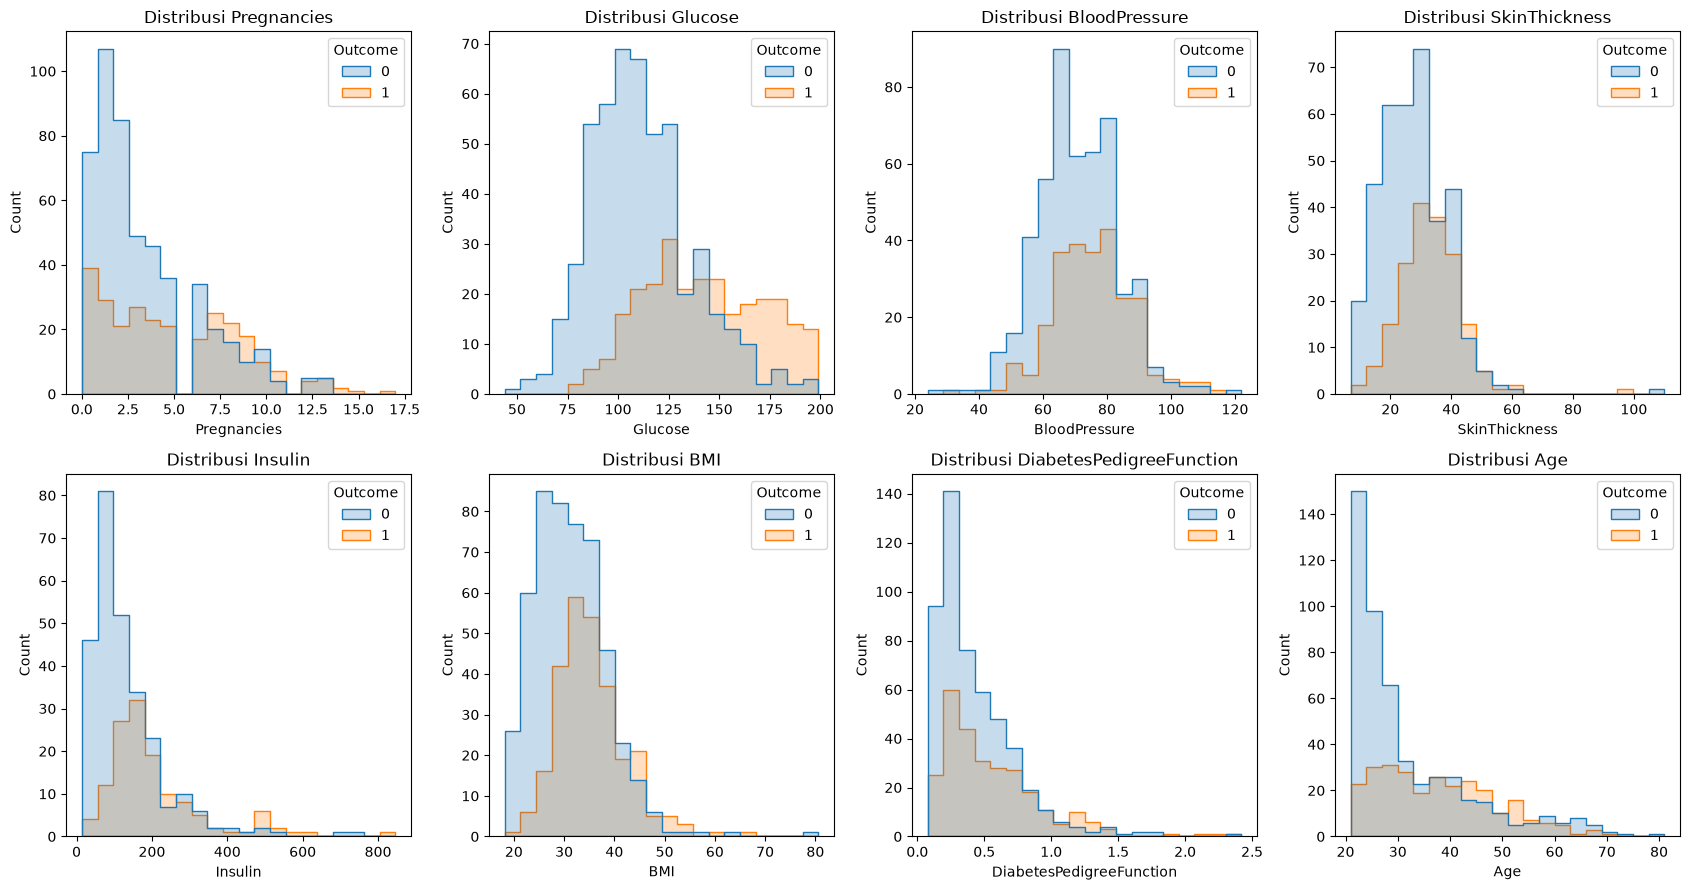

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
for feature, ax in zip(FEATURES, axes.ravel()):
    sns.histplot(
        data=data, x=feature, hue=TARGET,
        bins=20, element="step", ax=ax,
    )
    ax.set_title(f"Distribusi {feature}")

plt.tight_layout()
plt.show()


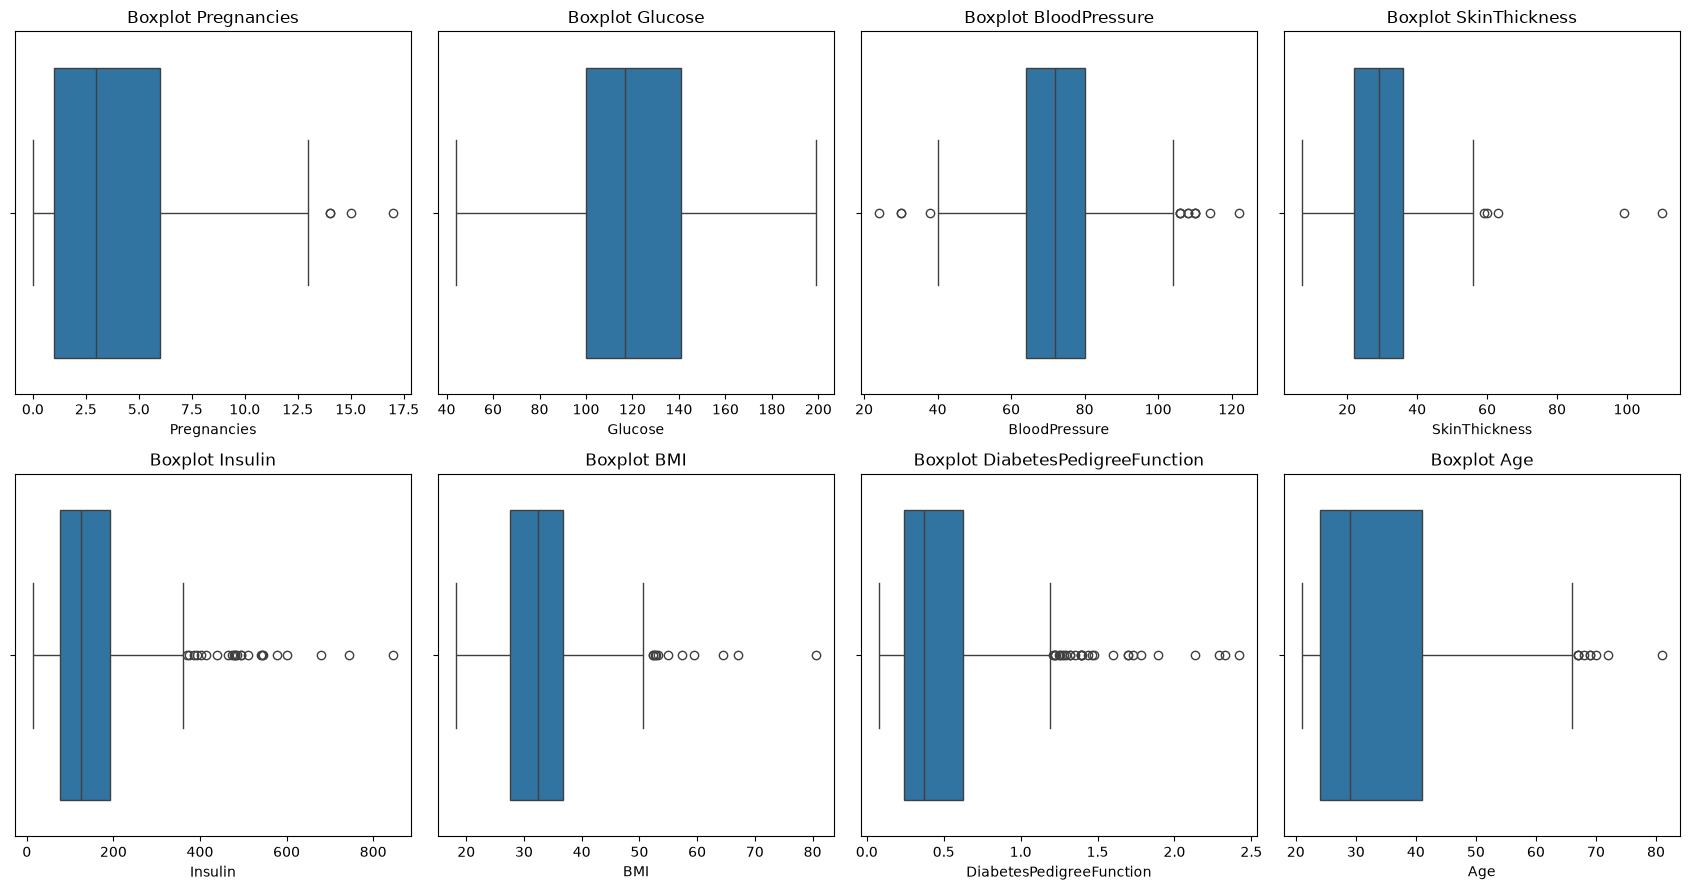

Jumlah nilai di luar batas IQR per fitur:
DiabetesPedigreeFunction    29
Insulin                     24
BloodPressure               14
BMI                         11
Age                          9
SkinThickness                5
Pregnancies                  4
Glucose                      0
dtype: int64


In [10]:
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
for feature, ax in zip(FEATURES, axes.ravel()):
    sns.boxplot(data=data, x=feature, ax=ax)
    ax.set_title(f"Boxplot {feature}")
plt.tight_layout()
plt.show()

q1 = data[FEATURES].quantile(0.25)
q3 = data[FEATURES].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_counts = ((data[FEATURES] < lower) | (data[FEATURES] > upper)).sum()
print("Jumlah nilai di luar batas IQR per fitur:")
print(outlier_counts.sort_values(ascending=False))


In [11]:
categorical_features = data[FEATURES].select_dtypes(
    include=["object", "category"]
).columns.tolist()
print("Fitur kategori:", categorical_features)
print("Jika daftar kosong, encoding kategori tidak diperlukan.")


Fitur kategori: []
Jika daftar kosong, encoding kategori tidak diperlukan.


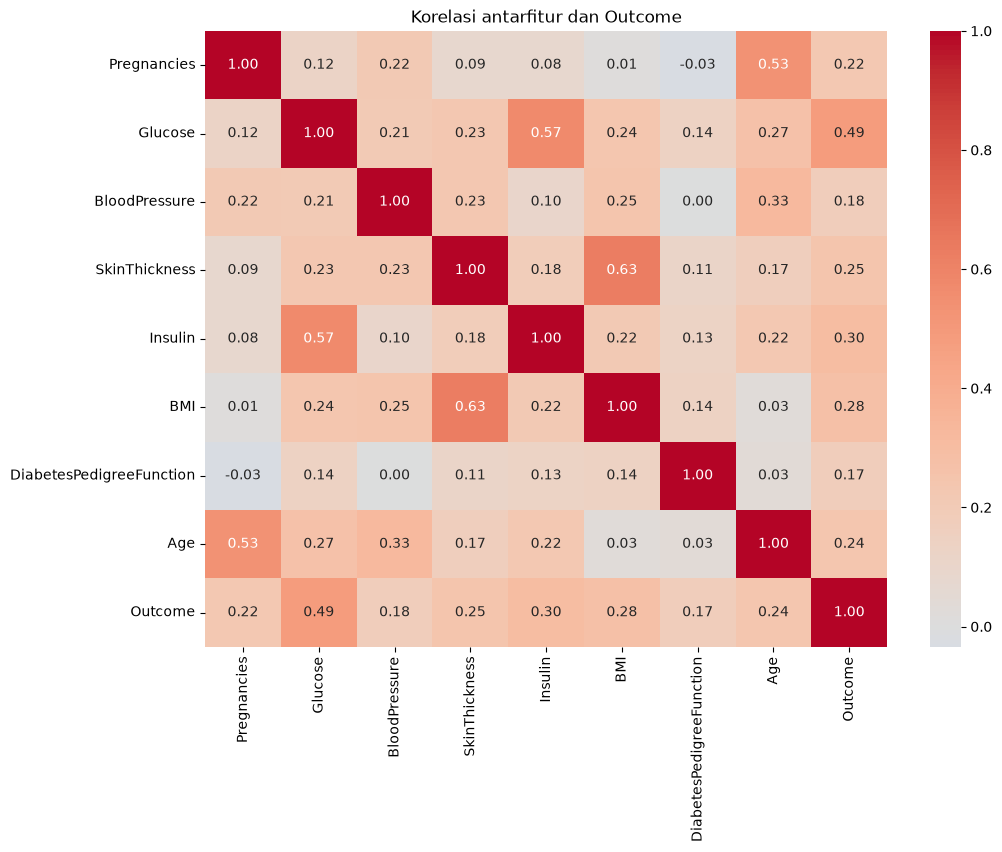

In [12]:
correlation_matrix = data[FEATURES + [TARGET]].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi antarfitur dan Outcome")
plt.show()


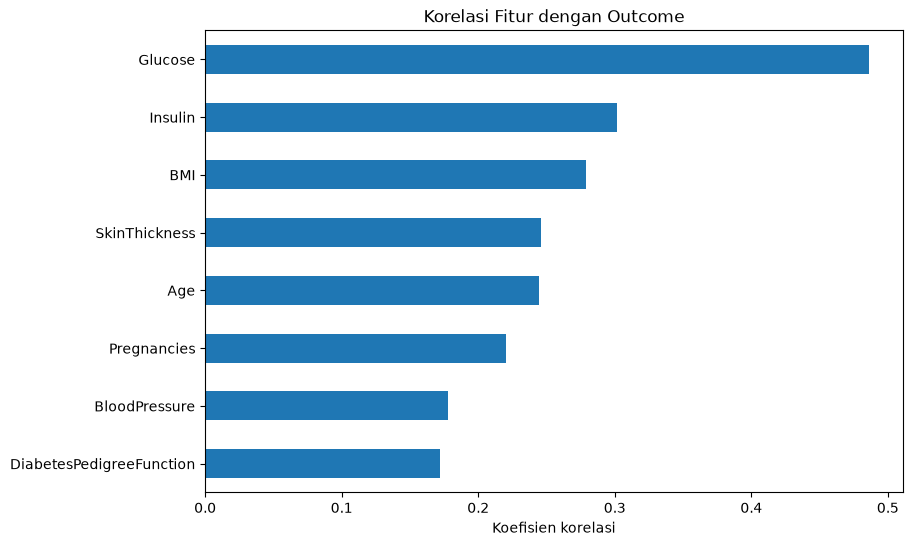

In [13]:
target_correlation = correlation_matrix[TARGET].drop(TARGET)
target_correlation = target_correlation.reindex(
    target_correlation.abs().sort_values(ascending=True).index
)

target_correlation.plot(kind="barh", figsize=(9, 6))
plt.title("Korelasi Fitur dengan Outcome")
plt.xlabel("Koefisien korelasi")
plt.show()


In [14]:
X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Jumlah data bersih:", len(X))
print("Jumlah data train:", len(X_train))
print("Jumlah data test:", len(X_test))
print("\nProporsi label train:")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("\nProporsi label test:")
print(y_test.value_counts(normalize=True).sort_index().round(3))


Jumlah data bersih: 778
Jumlah data train: 622
Jumlah data test: 156

Proporsi label train:
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

Proporsi label test:
Outcome
0    0.647
1    0.353
Name: proportion, dtype: float64


In [15]:
models = {
    "Logistic Regression": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000)),
    ]),
    "Random Forest": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(n_estimators=200, random_state=42)),
    ]),
    "Gradient Boosting": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", GradientBoostingClassifier(random_state=42)),
    ]),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: model selesai dilatih")


Logistic Regression: model selesai dilatih
Random Forest: model selesai dilatih
Gradient Boosting: model selesai dilatih


In [16]:
results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_probability = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision diabetes": precision_score(y_test, y_pred, zero_division=0),
        "Recall diabetes": recall_score(y_test, y_pred, zero_division=0),
        "F1 diabetes": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_probability),
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.sort_values("F1 diabetes", ascending=False).round(3))


,Accuracy,Precision diabetes,Recall diabetes,F1 diabetes,ROC-AUC
Model,,,,,
Random Forest,0.731,0.618,0.618,0.618,0.821
Gradient Boosting,0.744,0.653,0.582,0.615,0.823
Logistic Regression,0.712,0.600,0.545,0.571,0.815


                precision    recall  f1-score   support

Tidak diabetes       0.76      0.80      0.78       101
      Diabetes       0.60      0.55      0.57        55

      accuracy                           0.71       156
     macro avg       0.68      0.67      0.68       156
  weighted avg       0.71      0.71      0.71       156



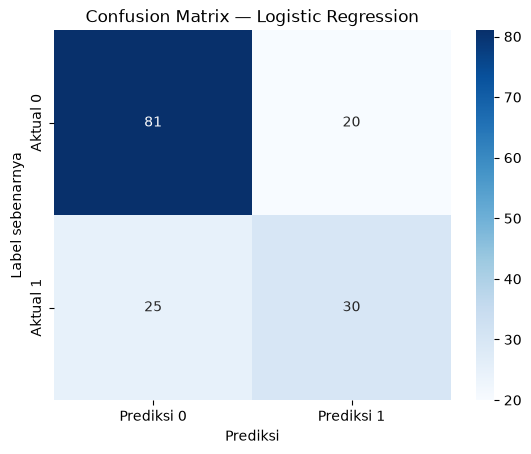

In [17]:
baseline = models["Logistic Regression"]
baseline_pred = baseline.predict(X_test)

print(classification_report(
    y_test,
    baseline_pred,
    labels=[0, 1],
    target_names=["Tidak diabetes", "Diabetes"],
    zero_division=0,
))

cm = confusion_matrix(y_test, baseline_pred, labels=[0, 1])
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Prediksi 0", "Prediksi 1"],
    yticklabels=["Aktual 0", "Aktual 1"],
)
plt.title("Confusion Matrix — Logistic Regression")
plt.xlabel("Prediksi")
plt.ylabel("Label sebenarnya")
plt.show()


In [18]:
MODEL_PATH = "diabetes_logistic_regression_pipeline.joblib"
joblib.dump(baseline, MODEL_PATH)
print(f"Pipeline disimpan ke: {MODEL_PATH}")


Pipeline disimpan ke: diabetes_logistic_regression_pipeline.joblib
